<div style="background: linear-gradient(90deg, #0b3c5d 0%, #1d6fa3 60%, #5fb3d9 100%); padding: 28px 30px; border-radius: 10px; color: white;">
  <div style="font-size: 30px; font-weight: 700; letter-spacing: 1px;">🌊 ONDAS, OLEAJE Y NIVEL DEL MAR</div>
  <div style="font-size: 19px; margin-top: 6px; opacity: 0.95;">Ejercicio 1 · Propagación desde indefinidas y rotura (Kaminsky–Kraus)</div>
  <div style="font-size: 13px; margin-top: 14px; opacity: 0.85;">Geomatics and Ocean Engineering Group · E.T.S. Ingenieros de Caminos, Canales y Puertos · Universidad de Cantabria</div>
</div>

<p align="left">
  <img src="../images/Image_1.png" width="100">&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<img src="../images/Image_2.png" width="100">
</p>

<div style="background-color: #f4f6f8; border-left: 6px solid #0b3c5d; padding: 12px 18px; border-radius: 6px;">
<b>📝 ENUNCIADO</b><br><br>

En un tramo de costa de batimetría recta y paralela con pendiente $m = 0.02$ se ha medido, en profundidades
indefinidas, un oleaje con $H_0 = 1$ m, $T = 12$ s y $\theta_0 = 30º$ respecto a la normal a las batimétricas.

<b>(a)</b> Calcula $L_0$, $C_0$ y $C_{g0}$.<br>
<b>(b)</b> Calcula las características del oleaje ($L$, $C$, $C_g$, $\theta$ y $H$) en la batimétrica $h = 15$ m.<br>
<b>(c)</b> Repite el cálculo en la batimétrica $h = 3$ m. ¿En qué profundidad relativa se encuentra? ¿Qué simplificaciones
puedes hacer? ¿Ha roto ya el oleaje en ese punto?<br>
<b>(d)</b> Calcula la profundidad de rotura $h_b$, la altura de ola en rotura $H_b$ y el ángulo $\theta_b$.<br><br>
Utiliza el criterio de rotura de Kaminsky–Kraus: $\dfrac{H_b}{h_b} = 1.2\,I_r^{0.27}$, con $I_r = \dfrac{m}{\sqrt{H_0/L_0}}$.

</div>

---

## 1. Librerías

In [1]:
import os.path as op
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Funciones propias del curso (carpeta ../functions)
sys.path.append(op.abspath('..'))
from functions.snell_mono import *
from functions.Breaking import *

pd.set_option('display.precision', 3)

---

## 2. Datos y método

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>H0</code>: altura de ola en indefinidas [m]</li>
<li><code>T</code>: periodo [s]</li>
<li><code>theta0</code>: ángulo respecto a la normal en indefinidas [º]</li>
<li><code>m</code>: pendiente de la playa [-]</li>
</ul>
</div>

In [2]:
H0 = 1.0       # [m]
T = 12.0       # [s]
theta0 = 30.0  # [º]
m = 0.02       # [-]

Con batimetría recta y paralela el procedimiento es siempre el mismo: el **periodo se conserva**, la **dirección**
cambia según la ley de Snell y la **altura de ola** según los coeficientes de asomeramiento y refracción:

$$ \frac{\sin\theta}{C} = \frac{\sin\theta_0}{C_0}, \qquad H = H_0\,K_s\,K_r, \qquad
K_s = \sqrt{\frac{C_{g0}}{C_g}}, \qquad K_r = \sqrt{\frac{\cos\theta_0}{\cos\theta}} $$

Lo único que cambia de una profundidad a otra es cómo se obtienen $L$, $C$ y $C_g$:

| Profundidad | Criterio | $L$ | $C$ | $C_g$ |
|---|---|---|---|---|
| Indefinidas | $h/L > 1/2$ | $L_0 = gT^2/2\pi$ | $C_0 = L_0/T$ | $C_0/2$ |
| Intermedias | $1/20 < h/L < 1/2$ | $L = L_0\tanh(2\pi h/L)$ | $L/T$ | $nC$, $\; n = \frac{1}{2}\left(1 + \frac{2kh}{\sinh 2kh}\right)$ |
| Someras | $h/L < 1/20$ | $T\sqrt{gh}$ | $\sqrt{gh}$ | $C$ |

En el código, las profundidades indefinidas se indican con `h = np.inf`.

---

## 3. (a) Profundidades indefinidas

In [3]:
L0, _, C0 = waves_dispersion(T, np.inf)
Cg0 = cg(L0, T, np.inf)

print(f'L0  = gT²/2π = {L0:.1f} m')
print(f'C0  = L0/T   = {C0:.2f} m/s')
print(f'Cg0 = C0/2   = {Cg0:.2f} m/s')

L0  = gT²/2π = 224.8 m
C0  = L0/T   = 18.74 m/s
Cg0 = C0/2   = 9.37 m/s


---

## 4. (b) Batimétrica h = 15 m

In [4]:
h_15 = 15  # [m]
print(f'h/L0 = {h_15 / L0:.3f}  ->  1/20 < h/L0 < 1/2: profundidades intermedias, hay que resolver la dispersión')
print()

# 1. Dispersión: longitud de onda, celeridad y celeridad de grupo
L_15, _, C_15 = waves_dispersion(T, h_15)
Cg_15 = cg(L_15, T, h_15)
print(f'L  = {L_15:.1f} m,   C = L/T = {C_15:.2f} m/s,   n = {Cg_15 / C_15:.3f},   Cg = n·C = {Cg_15:.2f} m/s')

# 2. Ley de Snell: sin θ / C = sin θ0 / C0
theta_15 = theta(C0, C_15, theta0)
print(f'sin θ = C/C0 · sin θ0 = {C_15 / C0:.3f} · {np.sin(np.radians(theta0)):.3f}  ->  θ = {theta_15:.1f}º')

# 3. Coeficientes de asomeramiento y refracción
Ks_15 = Ks(Cg0, Cg_15)
Kr_15 = Kr(theta0, theta_15)
print(f'Ks = √(Cg0/Cg) = {Ks_15:.3f},   Kr = √(cos θ0 / cos θ) = {Kr_15:.3f}')

# 4. Altura de ola
H_15 = H0 * Ks_15 * Kr_15
print(f'H  = H0 · Ks · Kr = {H0} · {Ks_15:.3f} · {Kr_15:.3f} = {H_15:.2f} m')

h/L0 = 0.067  ->  1/20 < h/L0 < 1/2: profundidades intermedias, hay que resolver la dispersión

L  = 135.4 m,   C = L/T = 11.28 m/s,   n = 0.869,   Cg = n·C = 9.80 m/s
sin θ = C/C0 · sin θ0 = 0.602 · 0.500  ->  θ = 17.5º
Ks = √(Cg0/Cg) = 0.978,   Kr = √(cos θ0 / cos θ) = 0.953
H  = H0 · Ks · Kr = 1.0 · 0.978 · 0.953 = 0.93 m


<div style="background-color: #eaf7ea; border-left: 6px solid #2ca02c; padding: 10px 16px; border-radius: 6px;">
✅ En $h = 15$ m: $L = 135.4$ m, $C = 11.28$ m/s, $C_g = 9.80$ m/s, $\theta = 17.5º$ y $H = 0.93$ m.
</div>

---

## 5. (c) Batimétrica h = 3 m

### <span style='color:#1d6fa3'>5.1 Profundidad relativa y simplificaciones</span>

In [5]:
h_3 = 3  # [m]

# Suponiendo aguas someras: C = Cg = √(gh), L = C·T
C_3s = np.sqrt(g * h_3)
L_3s = C_3s * T
Cg_3s = C_3s                                  # n = 1: la onda no es dispersiva
print(f'Suponiendo someras: L ≈ T·√(gh) = {L_3s:.1f} m  ->  h/L = {h_3 / L_3s:.3f} < 1/20 = 0.05: la hipótesis se cumple')
print(f'C = Cg = √(gh) = {C_3s:.2f} m/s')

theta_3s = theta(C0, C_3s, theta0)            # Snell
Ks_3s, Kr_3s = Ks(Cg0, Cg_3s), Kr(theta0, theta_3s)
H_3s = H0 * Ks_3s * Kr_3s
print(f'θ = {theta_3s:.1f}º,   Ks = {Ks_3s:.3f},   Kr = {Kr_3s:.3f},   H = {H_3s:.2f} m')

Suponiendo someras: L ≈ T·√(gh) = 65.1 m  ->  h/L = 0.046 < 1/20 = 0.05: la hipótesis se cumple
C = Cg = √(gh) = 5.42 m/s
θ = 8.3º,   Ks = 1.314,   Kr = 0.936,   H = 1.23 m


Para ver el error de la aproximación, repetimos los mismos pasos con la ecuación de la dispersión completa:

In [6]:
L_3, _, C_3 = waves_dispersion(T, h_3)        # dispersión
Cg_3 = cg(L_3, T, h_3)
theta_3 = theta(C0, C_3, theta0)              # Snell
Ks_3, Kr_3 = Ks(Cg0, Cg_3), Kr(theta0, theta_3)
H_3 = H0 * Ks_3 * Kr_3

apartado_c = pd.DataFrame({
    'L [m]':    [L_3s, L_3],
    'C [m/s]':  [C_3s, C_3],
    'n':        [Cg_3s / C_3s, Cg_3 / C_3],
    'Cg [m/s]': [Cg_3s, Cg_3],
    'θ [º]':    [theta_3s, theta_3],
    'Ks':       [Ks_3s, Ks_3],
    'Kr':       [Kr_3s, Kr_3],
    'H [m]':    [H_3s, H_3],
}, index=['Someras', 'Dispersión completa'])
apartado_c['Error H [%]'] = 100 * (apartado_c['H [m]'] / H_3 - 1)
apartado_c

,L [m],C [m/s],n,Cg [m/s],θ [º],Ks,Kr,H [m],Error H [%]
Someras,65.099,5.425,1.000,5.425,8.324,1.314,0.936,1.229,-2.069
Dispersión completa,64.188,5.349,0.972,5.201,8.207,1.342,0.935,1.255,0.000


En someras la onda **no es dispersiva** ($n = 1$, $C = C_g = \sqrt{gh}$). El error de la aproximación en $H$ es de un 2 %.

### <span style='color:#1d6fa3'>5.2 ¿Ha roto ya el oleaje?</span>

La ola rompe cuando su altura alcanza una fracción $\gamma_b$ de la profundidad, $H_b/h_b = \gamma_b$. El criterio de
Kaminsky–Kraus da $\gamma_b$ en función de la pendiente y del peralte del oleaje a través del número de Iribarren.

In [7]:
Ir = Iro(m, H0, L0)
gamma_b = gamma_KaminskyKraus(m, H0, T)
print(f'Ir      = m / √(H0/L0) = {Ir:.3f}')
print(f'gamma_b = 1.2 · Ir^0.27 = {gamma_b:.3f}')
print()
print(f"En h = 3 m:  H/h = {H_3s:.2f}/3 = {H_3s / h_3:.2f}  <  gamma_b = {gamma_b:.3f}  ->  todavía NO ha roto")
print(f'Para romper en h = 3 m haría falta H = gamma_b · h = {gamma_b * h_3:.1f} m')

Ir      = m / √(H0/L0) = 0.300
gamma_b = 1.2 · Ir^0.27 = 0.867

En h = 3 m:  H/h = 1.23/3 = 0.41  <  gamma_b = 0.867  ->  todavía NO ha roto
Para romper en h = 3 m haría falta H = gamma_b · h = 2.6 m


<div style="background-color: #eaf7ea; border-left: 6px solid #2ca02c; padding: 10px 16px; border-radius: 6px;">
✅ En $h = 3$ m (someras): $L = 65.1$ m, $C = C_g = 5.42$ m/s, $\theta = 8.3º$ y $H = 1.23$ m. Como $H/h = 0.41 < \gamma_b = 0.867$, el oleaje todavía no ha roto.
</div>

---

## 6. (d) Rotura

Ahora la incógnita es la propia profundidad $h_b$: la ola rompe donde la altura propagada iguala a la altura de rotura,

$$ H(h_b) = H_0\,K_s(h_b)\,K_r(h_b) = \gamma_b\,h_b $$

Como $K_s$ y $K_r$ dependen de $h_b$, se resuelve **iterando**: se supone $h_b$, se calculan $C = C_g = \sqrt{g h_b}$
(la rotura se produce en someras), $\theta$ con Snell y $H = H_0 K_s K_r$, y se obtiene un nuevo $h_b = H/\gamma_b$.

### <span style='color:#1d6fa3'>6.1 Iteración a mano (aproximación de someras)</span>

In [8]:
hb = 2.0  # valor inicial [m]
filas = []
for it in range(1, 7):
    C_b = np.sqrt(g * hb)                     # someras: C = Cg = √(g·hb)
    theta_b = theta(C0, C_b, theta0)          # Snell
    H_b = H0 * Ks(Cg0, C_b) * Kr(theta0, theta_b)
    hb_nuevo = H_b / gamma_b                  # nueva profundidad de rotura
    filas.append({'Iteración': it, 'hb [m]': hb, 'C = Cg [m/s]': C_b, 'θ [º]': theta_b,
                  'H [m]': H_b, 'H/γb [m]': hb_nuevo})
    if abs(hb_nuevo - hb) < 0.005:
        break
    hb = hb_nuevo

iteraciones = pd.DataFrame(filas).set_index('Iteración')
iteraciones.round(2)

,hb [m],C = Cg [m/s],θ [º],H [m],H/γb [m]
Iteración,,,,,
1,2.00,4.43,6.79,1.36,1.57
2,1.57,3.92,6.01,1.44,1.66
3,1.66,4.04,6.19,1.42,1.64
4,1.64,4.01,6.14,1.43,1.65
5,1.65,4.02,6.16,1.43,1.64


In [9]:
# Rotura con la última iteración
Cb_s = np.sqrt(g * hb_nuevo)
Lb_s = Cb_s * T
thetab_s = theta(C0, Cb_s, theta0)
Hb_s = gamma_b * hb_nuevo
print(f'hb = {hb_nuevo:.2f} m,   Hb = γb·hb = {Hb_s:.2f} m,   θb = {thetab_s:.1f}º')
print(f'Comprobación: hb/Lb = {hb_nuevo / Lb_s:.3f} < 1/20  ->  la hipótesis de someras es correcta')

hb = 1.64 m,   Hb = γb·hb = 1.43 m,   θb = 6.2º
Comprobación: hb/Lb = 0.034 < 1/20  ->  la hipótesis de someras es correcta


### <span style='color:#1d6fa3'>6.2 Con la ecuación de la dispersión completa (funciones del curso)</span>

`hb_calculation_vec` resuelve la misma ecuación $H(h_b) = \gamma_b h_b$ por bisección, con la dispersión completa. Le pasamos el criterio de Kaminsky–Kraus como una función $H_b(T, h, m)$.

In [10]:
criterio_KK = lambda T, h, m: gamma_b * h

hb_completa = float(hb_calculation_vec(H0, T, theta0, np.inf, m, criterio=criterio_KK))
Hb_completa, thetab_completa = snell_propagation(H0, T, theta0, np.inf, hb_completa)
print(f'hb = {hb_completa:.2f} m,   Hb = {Hb_completa:.2f} m,   θb = {thetab_completa:.1f}º')

hb = 1.66 m,   Hb = 1.44 m,   θb = 6.1º


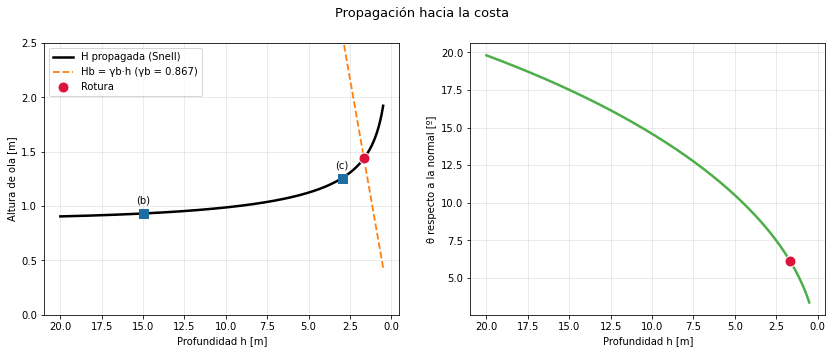

In [11]:
h_perfil = np.linspace(0.5, 20, 400)
H_perfil, theta_perfil = snell_propagation(H0, T, theta0, np.inf, h_perfil)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].plot(h_perfil, H_perfil, c='k', lw=2.5, label='H propagada (Snell)')
axs[0].plot(h_perfil, gamma_b * h_perfil, c='#ff7f0e', lw=1.8, ls='--', label=f'Hb = γb·h (γb = {gamma_b:.3f})')
axs[0].plot(hb_completa, Hb_completa, 'o', ms=11, c='crimson', mec='white', label='Rotura')
for hh, nombre in [(15, '(b)'), (3, '(c)')]:
    Hh, _ = snell_propagation(H0, T, theta0, np.inf, hh)
    axs[0].plot(hh, Hh, 's', ms=9, c='#1d6fa3')
    axs[0].annotate(nombre, (hh, Hh), textcoords='offset points', xytext=(0, 10), ha='center')
axs[0].set_ylim(0, 2.5)
axs[0].set_ylabel('Altura de ola [m]')
axs[0].legend()

axs[1].plot(h_perfil, theta_perfil, c='#4daf4a', lw=2.5)
axs[1].plot(hb_completa, thetab_completa, 'o', ms=11, c='crimson', mec='white')
axs[1].set_ylabel('θ respecto a la normal [º]')

for ax in axs:
    ax.invert_xaxis()
    ax.set_xlabel('Profundidad h [m]')
    ax.grid(alpha=0.3)
fig.suptitle('Propagación hacia la costa', fontsize=13)
plt.show()

---

## 7. Resumen de resultados

In [12]:
resumen = pd.DataFrame({
    'Valor': [L0, C0, Cg0, L_15, theta_15, H_15,
              L_3s, theta_3s, H_3s, gamma_b,
              hb_nuevo, Hb_s, thetab_s, hb_completa],
}, index=['(a) L0 [m]', '(a) C0 [m/s]', '(a) Cg0 [m/s]', '(b) L [m]', '(b) θ [º]', '(b) H [m]',
          '(c) L [m] (someras)', '(c) θ [º] (someras)', '(c) H [m] (someras)', '(c) γb',
          '(d) hb [m] (someras)', '(d) Hb [m] (someras)', '(d) θb [º] (someras)', '(d) hb [m] (dispersión completa)'])
resumen['Valor'] = resumen['Valor'].astype(float).round(3)
resumen

,Valor
(a) L0 [m],224.829
(a) C0 [m/s],18.736
(a) Cg0 [m/s],9.368
(b) L [m],135.352
(b) θ [º],17.518
(b) H [m],0.932
(c) L [m] (someras),65.099
(c) θ [º] (someras),8.324
(c) H [m] (someras),1.229
(c) γb,0.867
